# Pruebas de LightGBM

Predecimos el **índice de facturación diaria suponiendo que la tienda abre**. Comparamos LightGBM con la mediana histórica por día de la semana, usando el Gold real y el mismo índice base 100 que en los notebooks anteriores.

Validamos con cortes trimestrales y anuales de 2023–2024. Después entrenamos hasta 2024 y predecimos 2025 completo de una sola vez; sus ventas reales solo se usan para evaluar los días abiertos. Probamos configuraciones, horizontes y ventanas móviles.

**Confidencialidad:** las salidas muestran índices, porcentajes y recuentos, no importes. Pueden contener patrones comerciales y deben revisarse antes de compartir el notebook.

## 1. Datos e índice

La media de las ventas de los días abiertos de 2022 es el índice 100. Comprobamos la cobertura diaria y la validez de los campos del Gold. Los cierres se mantienen en el calendario como valores no observados; LightGBM se ajusta **solo con días abiertos**, sin tratar cierres como ventas cero. Suponemos que el calendario de festivos se conoce antes de cada predicción.

In [ ]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMRegressor

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
DATASET = PROJECT_ROOT / "data" / "processed" / "ventas_gold.csv"

ventas = pd.read_csv(DATASET, encoding="utf-8-sig", dtype=str)
faltantes = {"fecha", "total", "es_festivo"} - set(ventas.columns)
if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {sorted(faltantes)}")
ventas = ventas[["fecha", "total", "es_festivo"]].copy()
ventas["fecha"] = pd.to_datetime(ventas["fecha"], format="mixed", errors="coerce")
texto_total = ventas["total"].str.replace("€", "", regex=False).str.replace(" ", "", regex=False)
formato_espanol = texto_total.str.contains(",", na=False)
texto_total.loc[formato_espanol] = texto_total.loc[formato_espanol].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
ventas["total"] = pd.to_numeric(texto_total, errors="coerce")
ventas["es_festivo"] = pd.to_numeric(ventas["es_festivo"], errors="coerce")
fechas_esperadas = pd.date_range("2022-01-01", "2025-12-31", freq="D")
fechas_validas = ventas["fecha"].dropna()
controles = pd.Series({
    "Fechas inválidas": int(ventas["fecha"].isna().sum()),
    "Fechas duplicadas": int(fechas_validas.duplicated().sum()),
    "Fechas fuera del periodo": int((~fechas_validas.isin(fechas_esperadas)).sum()),
    "Fechas ausentes": len(fechas_esperadas.difference(fechas_validas)),
    "Totales no numéricos o infinitos": int((~np.isfinite(ventas["total"])).sum()),
    "Totales negativos": int(ventas["total"].lt(0).sum()),
    "Festivos no válidos": int((~ventas["es_festivo"].isin([0, 1])).sum()),
}, name="Incidencias")
display(controles.to_frame())
if controles.gt(0).any():
    raise ValueError("Revisa las incidencias antes de continuar.")
base_2022 = ventas.loc[ventas["fecha"].dt.year.eq(2022) & ventas["total"].gt(0), "total"].mean()
if not np.isfinite(base_2022) or base_2022 <= 0:
    raise ValueError("No se puede calcular la referencia de los días abiertos de 2022.")
ventas["indice"] = (100 * ventas["total"] / base_2022).where(ventas["total"].gt(0))
datos = ventas.set_index("fecha")[["indice", "es_festivo"]].sort_index().asfreq("D")
del ventas, texto_total, base_2022
print("Controles superados. Índice calculado; los cierres no se usan como observaciones.")

,Incidencias
Fechas inválidas,0
Fechas duplicadas,0
Fechas fuera del periodo,0
Fechas ausentes,0
Totales no numéricos o infinitos,0
Totales negativos,0
Festivos no válidos,0


Controles superados. Índice calculado; los cierres no se usan como observaciones.


## 2. Variables y configuraciones

LightGBM combina árboles de decisión. Todos los modelos usan indicadores binarios del **día de la semana**, **mes** y **festivo**. Los árboles pueden aprender interacciones entre esas variables. Una configuración añade el día del mes y un indicador de sábado en agosto, septiembre, octubre o diciembre; esos meses proceden del EDA, que ya incluía 2025.

Solo empleamos variables conocidas para todas las fechas futuras: no usamos ventas del horizonte, lags ni medias calculadas con 2025. Tampoco añadimos el año: con estas variables LightGBM aprende patrones de calendario, pero **no extrapola por sí mismo una tendencia anual**.

| Configuración | Objetivo | Hojas máximas | Mínimo por hoja | Variables adicionales |
|---|---|---:|---:|---|
| Inicial | Error cuadrático (L2) | 7 | 20 | Ninguna |
| Error absoluto | Error absoluto (L1) | 7 | 20 | Ninguna |
| Más simple | L1 | 3 | 30 | Ninguna |
| Más detalle | L1 | 15 | 10 | Ninguna |
| Calendario ampliado | L1 | 7 | 20 | Día del mes y sábado en temporada alta |

El objetivo L1 penaliza errores absolutos, coherente con la suma de errores del WAPE sobre un mismo conjunto de días; eso no garantiza que gane en validación. Las configuraciones más complejas pueden sobreajustar, especialmente con pocos domingos abiertos.

In [ ]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]
MESES_TEMPORADA_ALTA = (8, 9, 10, 12)
NIVEL_COBERTURA = 0.90
SEMILLA = 42
CONFIGURACIONES = {
    "Inicial": {"objective": "regression", "num_leaves": 7, "min_child_samples": 20, "n_estimators": 200, "detalles": False},
    "Error absoluto": {"objective": "regression_l1", "num_leaves": 7, "min_child_samples": 20, "n_estimators": 200, "detalles": False},
    "Más simple": {"objective": "regression_l1", "num_leaves": 3, "min_child_samples": 30, "n_estimators": 200, "detalles": False},
    "Más detalle": {"objective": "regression_l1", "num_leaves": 15, "min_child_samples": 10, "n_estimators": 300, "detalles": False},
    "Calendario ampliado": {"objective": "regression_l1", "num_leaves": 7, "min_child_samples": 20, "n_estimators": 200, "detalles": True},
}

def variables_calendario(calendario, detalles=False):
    variables = pd.DataFrame(index=calendario.index)
    for dia, nombre in enumerate(DIAS):
        variables[f"dia_{nombre}"] = (calendario.index.day_of_week == dia).astype(int)
    for mes in range(1, 13):
        variables[f"mes_{mes:02d}"] = (calendario.index.month == mes).astype(int)
    variables["es_festivo"] = calendario["es_festivo"].astype(int)
    if detalles:
        variables["dia_del_mes"] = calendario.index.day
        variables["sabado_temporada_alta"] = ((calendario.index.day_of_week == 5) & calendario.index.month.isin(MESES_TEMPORADA_ALTA)).astype(int)
    return variables

def predecir_periodo(datos, inicio, fin, configuracion, inicio_entrenamiento=None):
    inicio, fin = pd.Timestamp(inicio), pd.Timestamp(fin)
    desde = datos.index.min() if inicio_entrenamiento is None else pd.Timestamp(inicio_entrenamiento)
    if desde < datos.index.min() or desde >= inicio:
        raise ValueError("La ventana de entrenamiento solicitada no está disponible.")
    entrenamiento = datos.loc[desde:inicio - pd.Timedelta(days=1)]
    futuro = datos.loc[inicio:fin]
    fechas = pd.date_range(inicio, fin, freq="D")
    if not entrenamiento.index.equals(pd.date_range(desde, inicio - pd.Timedelta(days=1), freq="D")) or not futuro.index.equals(fechas):
        raise ValueError("Falta cobertura diaria en el entrenamiento o en el periodo de predicción.")
    abiertos = entrenamiento.loc[entrenamiento["indice"].notna()]
    medianas = abiertos["indice"].groupby(abiertos.index.day_of_week).median()
    if abiertos.empty or len(medianas) != 7:
        raise ValueError("No hay días abiertos de entrenamiento para todos los días de la semana.")
    variables_entrenamiento = variables_calendario(abiertos, configuracion["detalles"])
    variables_futuras = variables_calendario(futuro, configuracion["detalles"])
    if not variables_entrenamiento.columns.equals(variables_futuras.columns):
        raise ValueError("Las variables de entrenamiento y predicción no coinciden.")
    modelo = LGBMRegressor(
        objective=configuracion["objective"], num_leaves=configuracion["num_leaves"],
        min_child_samples=configuracion["min_child_samples"], n_estimators=configuracion["n_estimators"],
        learning_rate=0.05, reg_lambda=1.0, random_state=SEMILLA, n_jobs=1, verbosity=-1,
    )
    modelo.fit(variables_entrenamiento, abiertos["indice"])
    predicciones = pd.DataFrame({
        "fecha": fechas, "lightgbm": modelo.predict(variables_futuras),
        "baseline": fechas.day_of_week.map(medianas).to_numpy(),
    })
    if not np.isfinite(predicciones.drop(columns="fecha").to_numpy()).all():
        raise ValueError("Hay predicciones no finitas.")
    return predicciones, modelo

def evaluar_periodo(datos, inicio, fin, configuracion, inicio_entrenamiento=None):
    predicciones, modelo = predecir_periodo(datos, inicio, fin, configuracion, inicio_entrenamiento)
    reales = datos.loc[pd.Timestamp(inicio):pd.Timestamp(fin), "indice"].dropna().rename("indice")
    comparacion = predicciones.merge(reales.rename_axis("fecha"), on="fecha", how="inner", validate="one_to_one")
    if comparacion.empty or len(comparacion) != len(reales):
        raise ValueError("No hay días abiertos o faltan predicciones para evaluarlos.")
    return comparacion, modelo

def metricas(reales, predicciones):
    if reales.empty or not np.isfinite(reales).all() or reales.le(0).any() or not np.isfinite(predicciones).all():
        raise ValueError("Las métricas requieren índices reales positivos y valores finitos.")
    error = predicciones - reales
    return pd.Series({"Días abiertos": len(reales), "MAE (puntos de índice)": error.abs().mean(),
                      "MAPE (%)": 100 * error.abs().div(reales).mean(),
                      "WAPE (%)": 100 * error.abs().sum() / reales.sum(),
                      "Sesgo (puntos de índice)": error.mean()})

def comparar(resultados, nombre_referencia="Inicial"):
    referencia = resultados[nombre_referencia].reset_index(drop=True)
    filas = {"Baseline: mediana día semanal": metricas(referencia["indice"], referencia["baseline"])}
    for nombre, resultado in resultados.items():
        resultado = resultado.reset_index(drop=True)
        if not resultado["fecha"].equals(referencia["fecha"]) or not resultado["indice"].equals(referencia["indice"]):
            raise ValueError("Los modelos no se evalúan sobre los mismos días abiertos.")
        filas[nombre] = metricas(resultado["indice"], resultado["lightgbm"])
    return pd.DataFrame(filas).T

def resumen_intervalo(reales, inferior, superior):
    return pd.Series({"Días abiertos": len(reales),
                      "Cobertura observada (%)": 100 * reales.between(inferior, superior).mean(),
                      "Anchura media (puntos de índice)": (superior - inferior).mean()})

## 3. Validación temporal y selección

En cada corte entrenamos solo con los días abiertos anteriores y predecimos todo el trimestre o año de una vez. Usamos los ocho trimestres y los dos años de 2023–2024, como en SARIMAX y Prophet. **MAE** se expresa en puntos de índice; **MAPE** y **WAPE** en porcentaje. El sesgo es predicción menos realidad. El WAPE conjunto se calcula sumando los errores y los índices reales de todos los días, no promediando los porcentajes de cada corte.

Elegimos la configuración por WAPE anual conjunto, con el WAPE trimestral como desempate. El ranking usa valores sin redondear; diferencias muy pequeñas no demuestran una mejora práctica. Solo tenemos dos cortes anuales y varias configuraciones, así que el resultado es orientativo. No usamos las ventas de 2025 para elegir, aunque ese año ya se exploró durante el proyecto.

In [ ]:
validaciones = {}
for nombre, configuracion in CONFIGURACIONES.items():
    print(f"Validando {nombre}...")
    cortes = []
    for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
        resultado, _ = evaluar_periodo(datos, trimestre.start_time, trimestre.end_time.normalize(), configuracion)
        resultado["trimestre"] = str(trimestre)
        cortes.append(resultado)
    anios = []
    for anio in (2023, 2024):
        resultado, _ = evaluar_periodo(datos, f"{anio}-01-01", f"{anio}-12-31", configuracion)
        resultado["anio_validacion"] = anio
        anios.append(resultado)
    validaciones[nombre] = {"trimestral": pd.concat(cortes, ignore_index=True), "anual": pd.concat(anios, ignore_index=True)}

for horizonte in ("trimestral", "anual"):
    print(f"Validación {horizonte} conjunta:")
    display(comparar({nombre: resultados[horizonte] for nombre, resultados in validaciones.items()}).round(2))
filas_anuales = []
for anio in (2023, 2024):
    resultados = {nombre: v["anual"].loc[v["anual"]["anio_validacion"].eq(anio)] for nombre, v in validaciones.items()}
    resumen = comparar(resultados).reset_index(names="Modelo")
    resumen["Año"] = anio
    filas_anuales.append(resumen)
print("Validación anual por año:")
display(pd.concat(filas_anuales, ignore_index=True).set_index(["Año", "Modelo"]).round(2))

ranking = pd.DataFrame({
    "WAPE anual": {nombre: metricas(v["anual"]["indice"], v["anual"]["lightgbm"])["WAPE (%)"] for nombre, v in validaciones.items()},
    "WAPE trimestral": {nombre: metricas(v["trimestral"]["indice"], v["trimestral"]["lightgbm"])["WAPE (%)"] for nombre, v in validaciones.items()},
}).sort_values(["WAPE anual", "WAPE trimestral"], kind="stable")
configuracion_elegida = ranking.index[0]
print(f"Configuración elegida mediante validación: {configuracion_elegida}")
display(ranking.round(5))

filas_trimestrales = []
for trimestre in pd.period_range("2023Q1", "2024Q4", freq="Q"):
    resultados = {nombre: v["trimestral"].loc[v["trimestral"]["trimestre"].eq(str(trimestre))] for nombre, v in validaciones.items()}
    resumen = comparar(resultados).reset_index(names="Modelo")
    resumen["Trimestre"] = str(trimestre)
    filas_trimestrales.append(resumen)
print("Validación por trimestre:")
with pd.option_context("display.max_rows", None):
    display(pd.concat(filas_trimestrales, ignore_index=True).set_index(["Trimestre", "Modelo"]).round(2))

sabados_validacion = {nombre: v["anual"].loc[v["anual"]["fecha"].dt.day_of_week.eq(5) & v["anual"]["fecha"].dt.month.isin(MESES_TEMPORADA_ALTA)] for nombre, v in validaciones.items()}
print("Sábados abiertos de temporada alta en la validación anual conjunta:")
display(comparar(sabados_validacion).round(2))

Validando Inicial...


Validando Error absoluto...


Validando Más simple...
Validando Más detalle...


Validando Calendario ampliado...


Validación trimestral conjunta:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,618.0,29.14,31.89,26.07,-9.17
Inicial,618.0,27.57,32.47,24.67,-4.57
Error absoluto,618.0,27.77,31.28,24.84,-7.23
Más simple,618.0,28.21,31.70,25.24,-7.89
Más detalle,618.0,27.56,30.62,24.66,-7.84
Calendario ampliado,618.0,27.97,31.49,25.02,-7.52


... (6 outputs left out)

Validación por trimestre:


Días abiertos  \
Trimestre Modelo                                         
2023Q1    Baseline: mediana día semanal           78.0   
          Inicial                                 78.0   
          Error absoluto                          78.0   
          Más simple                              78.0   
          Más detalle                             78.0   
          Calendario ampliado                     78.0   
2023Q2    Baseline: mediana día semanal           81.0   
          Inicial                                 81.0   
          Error absoluto                          81.0   
          Más simple                              81.0   
          Más detalle                             81.0   
          Calendario ampliado                     81.0   
2023Q3    Baseline: mediana día semanal           77.0   
          Inicial                                 77.0   
          Error absoluto                          77.0   
          Más simple                              77.0   
          Más detalle                             77.0   
          Calendario ampliado                     77.0   
2023Q4    Baseline: mediana día semanal           75.0   
          Inicial                                 75.0   
          Error absoluto                          75.0   
          Más simple                              75.0   
          Más detalle                             75.0   
          Calendario ampliado                     75.0   
2024Q1    Baseline: mediana día semanal           77.0   
          Inicial                                 77.0   
          Error absoluto                          77.0   
          Más simple                              77.0   
          Más detalle                             77.0   
          Calendario ampliado                     77.0   
2024Q2    Baseline: mediana día semanal           76.0   
          Inicial                                 76.0   
          Error absoluto                          76.0   
          Más simple                              76.0   
          Más detalle                             76.0   
          Calendario ampliado                     76.0   
2024Q3    Baseline: mediana día semanal           78.0   
          Inicial                                 78.0   
          Error absoluto                          78.0   
          Más simple                              78.0   
          Más detalle                             78.0   
          Calendario ampliado                     78.0   
2024Q4    Baseline: mediana día semanal           76.0   
          Inicial                                 76.0   
          Error absoluto                          76.0   
          Más simple                              76.0   
          Más detalle                             76.0   
          Calendario ampliado                     76.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Trimestre Modelo                                                            
2023Q1    Baseline: mediana día semanal                   23.06     34.30   
          Inicial                                         20.95     27.31   
          Error absoluto                                  20.90     26.83   
          Más simple                                      21.94     31.39   
          Más detalle                                     21.30     27.62   
          Calendario ampliado                             20.69     27.72   
2023Q2    Baseline: mediana día semanal                   25.78     26.37   
          Inicial                                         26.71     28.84   
          Error absoluto                                  27.15     26.81   
          Más simple                                      26.52     26.63   
          Más detalle                                     27.64     26.86   
          Calendario ampliado                             26.54     26.45   
2023Q3    Baseline: mediana día semanal                   33.7

Sábados abiertos de temporada alta en la validación anual conjunta:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,35.0,51.46,25.53,27.14,-38.66
Inicial,35.0,42.54,22.21,22.44,-22.84
Error absoluto,35.0,45.06,23.58,23.77,-24.87
Más simple,35.0,48.07,24.88,25.36,-28.90
Más detalle,35.0,44.38,23.14,23.41,-23.72
Calendario ampliado,35.0,45.48,24.37,23.99,-21.22


## 4. Comparación retrospectiva de 2025

Ajustamos cada configuración con 2022–2024 y predecimos 2025 completo sin incorporar sus ventas. Después evaluamos únicamente los días que abrieron. Mostramos errores, sesgo, detalle por día y mes y la importancia de variables de la configuración elegida en validación. La importancia por ganancia describe el uso de variables por los árboles, no su dirección ni causalidad; puede repartirse entre variables correlacionadas.

Para obtener bandas orientativas del 90 %, usamos el percentil 90 de errores absolutos de validación anual de cada modelo; el baseline usa el mismo procedimiento y recorta su límite inferior a cero. Las bandas de LightGBM no se recortan. No son intervalos probabilísticos del propio modelo, su anchura es constante y la cobertura futura no está garantizada. La selección de configuraciones usa esa misma validación, por lo que la calibración también es exploratoria.

**2025 ya se ha explorado**: esta comparación es retrospectiva y no constituye una prueba ciega.

In [ ]:
test_2025, modelos_2025 = {}, {}
for nombre, configuracion in CONFIGURACIONES.items():
    test_2025[nombre], modelos_2025[nombre] = evaluar_periodo(datos, "2025-01-01", "2025-12-31", configuracion)
print("Errores globales de 2025:")
display(comparar(test_2025).round(2))
print(f"Configuración elegida mediante validación: {configuracion_elegida}")
print("Predicciones negativas en días abiertos:")
display(pd.Series({nombre: resultado["lightgbm"].lt(0).sum() for nombre, resultado in test_2025.items()}, name="Días").to_frame())

validacion_inicial = validaciones["Inicial"]["anual"]
margen_baseline = np.quantile((validacion_inicial["indice"] - validacion_inicial["baseline"]).abs(), NIVEL_COBERTURA, method="higher")
referencia = test_2025["Inicial"]
intervalos = {"Baseline: mediana día semanal": resumen_intervalo(referencia["indice"], (referencia["baseline"] - margen_baseline).clip(lower=0), referencia["baseline"] + margen_baseline)}
margenes_lightgbm = {}
for nombre, resultado in test_2025.items():
    validacion = validaciones[nombre]["anual"]
    margen = np.quantile((validacion["indice"] - validacion["lightgbm"]).abs(), NIVEL_COBERTURA, method="higher")
    margenes_lightgbm[nombre] = margen
    intervalos[nombre] = resumen_intervalo(resultado["indice"], resultado["lightgbm"] - margen, resultado["lightgbm"] + margen)
print("Cobertura y anchura de las bandas orientativas en 2025:")
display(pd.DataFrame(intervalos).T.round(2))

for campo, etiqueta in [("dia", "Día de la semana"), ("mes", "Mes")]:
    resultado = test_2025[configuracion_elegida]
    grupos = resultado["fecha"].dt.day_of_week if campo == "dia" else resultado["fecha"].dt.month
    filas = []
    for grupo in sorted(grupos.unique()):
        comparacion = resultado.loc[grupos.eq(grupo)].reset_index(drop=True)
        resumen = comparar({configuracion_elegida: comparacion}, nombre_referencia=configuracion_elegida).reset_index(names="Modelo")
        resumen[etiqueta] = DIAS[grupo] if campo == "dia" else grupo
        filas.append(resumen)
    print(f"Errores por {etiqueta.lower()} en 2025: baseline y configuración elegida")
    display(pd.concat(filas, ignore_index=True).set_index([etiqueta, "Modelo"]).round(2))

sabados_2025 = {nombre: resultado.loc[resultado["fecha"].dt.day_of_week.eq(5) & resultado["fecha"].dt.month.isin(MESES_TEMPORADA_ALTA)] for nombre, resultado in test_2025.items()}
print("Sábados abiertos de temporada alta en 2025:")
display(comparar(sabados_2025).round(2))
modelo_elegido = modelos_2025[configuracion_elegida]
ganancias = pd.Series(modelo_elegido.booster_.feature_importance(importance_type="gain"), index=modelo_elegido.feature_name_, name="Ganancia relativa (%)")
if ganancias.sum() <= 0:
    raise ValueError("El modelo no ha usado ninguna variable en sus divisiones.")
print("Importancia relativa por ganancia, sin interpretación causal:")
display((100 * ganancias / ganancias.sum()).sort_values(ascending=False).round(2).to_frame())

Errores globales de 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61
Inicial,308.0,28.54,34.88,27.89,7.43
Error absoluto,308.0,27.55,32.43,26.92,4.05
Más simple,308.0,27.41,32.65,26.78,2.96
Más detalle,308.0,28.05,32.76,27.41,4.22
Calendario ampliado,308.0,28.02,32.53,27.38,3.40


Configuración elegida mediante validación: Inicial
Predicciones negativas en días abiertos:


,Días
Inicial,0
Error absoluto,0
Más simple,0
Más detalle,0
Calendario ampliado,0


Cobertura y anchura de las bandas orientativas en 2025:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Baseline: mediana día semanal,308.0,95.13,127.62
Inicial,308.0,92.21,116.24
Error absoluto,308.0,93.18,120.22
Más simple,308.0,93.51,116.94
Más detalle,308.0,92.21,119.17
Calendario ampliado,308.0,92.86,119.34


... (4 outputs left out)

Sábados abiertos de temporada alta en 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,17.0,28.30,19.07,17.82,0.77
Inicial,17.0,33.48,23.96,21.08,15.16
Error absoluto,17.0,34.19,24.22,21.53,13.87
Más simple,17.0,30.63,21.73,19.29,11.51
Más detalle,17.0,36.45,26.79,22.95,23.42
Calendario ampliado,17.0,37.50,27.48,23.62,24.45


Importancia relativa por ganancia, sin interpretación causal:


,Ganancia relativa (%)
dia_Sábado,65.49
dia_Domingo,8.33
mes_08,3.90
mes_01,3.77
dia_Viernes,3.31
mes_12,3.18
es_festivo,1.71
mes_10,1.60
mes_07,1.48
mes_09,1.20


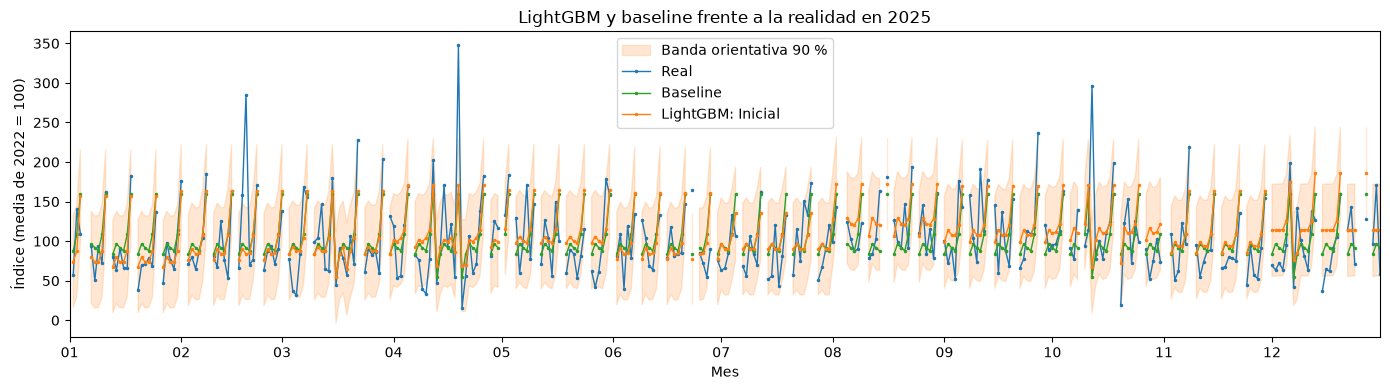

In [ ]:
fechas_2025 = pd.date_range("2025-01-01", "2025-12-31", freq="D")
grafica = test_2025[configuracion_elegida].set_index("fecha").reindex(fechas_2025)
margen = margenes_lightgbm[configuracion_elegida]
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(grafica.index, grafica["lightgbm"] - margen, grafica["lightgbm"] + margen, color="C1", alpha=0.18, label="Banda orientativa 90 %")
for columna, etiqueta, color in [("indice", "Real", "C0"), ("baseline", "Baseline", "C2"), ("lightgbm", f"LightGBM: {configuracion_elegida}", "C1")]:
    ax.plot(grafica.index, grafica[columna], label=etiqueta, color=color, marker=".", markersize=3, linewidth=1)
ax.set(title="LightGBM y baseline frente a la realidad en 2025", xlabel="Mes", ylabel="Índice (media de 2022 = 100)", xlim=(fechas_2025[0], fechas_2025[-1]))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m"))
ax.legend()
fig.tight_layout()
plt.show()

## 5. Ventanas móviles y entrenamiento sin 2022

Mantenemos la configuración elegida en validación y comparamos tres historiales: expansivo, último año y últimos dos años antes del corte. La ventana se desplaza entre cortes, pero el modelo no se reentrena dentro del horizonte. El baseline de referencia sigue usando todo el historial previo.

Validamos ventanas completas en los cuatro trimestres y el año de 2024. En la validación anual, la ventana de dos años y la expansiva usan el mismo historial (2022–2023); la de un año usa solo 2023. Los trimestres tienen un horizonte distinto y comparten datos de entrenamiento.

Para 2025 las ventanas usan 2022–2024, 2023–2024 o solo 2024. Las dos últimas excluyen 2022 del **ajuste**, pero no del cálculo de la referencia del índice 100. La comparación de 2025 es retrospectiva y sus resultados no son una evaluación independiente.

In [ ]:
def evaluar_ventanas(inicio, fin, expansiva):
    inicio = pd.Timestamp(inicio)
    resultados = {"Expansiva": expansiva.reset_index(drop=True)}
    for anios, nombre in [(1, "Último año"), (2, "Últimos dos años")]:
        desde = inicio - pd.DateOffset(years=anios)
        if desde < datos.index.min():
            raise ValueError(f"No hay {anios} años completos antes de {inicio.date()}.")
        resultado, _ = evaluar_periodo(datos, inicio, fin, CONFIGURACIONES[configuracion_elegida], desde)
        resultados[nombre] = resultado.reset_index(drop=True)
    comparar(resultados, nombre_referencia="Expansiva")
    return resultados

ventanas_trimestrales = {}
filas_ventanas = []
for trimestre in pd.period_range("2024Q1", "2024Q4", freq="Q"):
    original = validaciones[configuracion_elegida]["trimestral"]
    resultados = evaluar_ventanas(trimestre.start_time, trimestre.end_time.normalize(), original.loc[original["trimestre"].eq(str(trimestre))])
    ventanas_trimestrales[str(trimestre)] = resultados
    resumen = comparar(resultados, nombre_referencia="Expansiva").reset_index(names="Modelo")
    resumen["Trimestre"] = str(trimestre)
    filas_ventanas.append(resumen)
conjunto_ventanas = {nombre: pd.concat([v[nombre] for v in ventanas_trimestrales.values()], ignore_index=True) for nombre in ventanas_trimestrales["2024Q1"]}
print("Validación trimestral conjunta de 2024:")
display(comparar(conjunto_ventanas, nombre_referencia="Expansiva").round(2))
print("Validación por trimestre:")
display(pd.concat(filas_ventanas, ignore_index=True).set_index(["Trimestre", "Modelo"]).round(2))
original_2024 = validaciones[configuracion_elegida]["anual"]
ventanas_anuales = evaluar_ventanas("2024-01-01", "2024-12-31", original_2024.loc[original_2024["anio_validacion"].eq(2024)])
print("Validación anual de 2024:")
display(comparar(ventanas_anuales, nombre_referencia="Expansiva").round(2))

ventanas_2025 = evaluar_ventanas("2025-01-01", "2025-12-31", test_2025[configuracion_elegida])
print("Historial de entrenamiento para 2025:")
display(pd.DataFrame({
    "Inicio": [datos.index.min().date(), pd.Timestamp("2024-01-01").date(), pd.Timestamp("2023-01-01").date()],
    "Fin": [pd.Timestamp("2024-12-31").date()] * 3,
    "Días abiertos": [datos.loc[desde:"2024-12-31", "indice"].notna().sum() for desde in [datos.index.min(), "2024-01-01", "2023-01-01"]],
}, index=list(ventanas_2025)))
print("Errores de las ventanas en 2025:")
display(comparar(ventanas_2025, nombre_referencia="Expansiva").round(2))
print("Predicciones negativas en días abiertos:")
display(pd.Series({nombre: resultado["lightgbm"].lt(0).sum() for nombre, resultado in ventanas_2025.items()}, name="Días").to_frame())

Validación trimestral conjunta de 2024:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,307.0,29.72,27.50,26.51,-7.94
Expansiva,307.0,29.86,29.02,26.64,-2.76
Último año,307.0,29.88,29.85,26.65,0.48
Últimos dos años,307.0,29.71,28.90,26.51,-2.45


Validación por trimestre:


Días abiertos  \
Trimestre Modelo                                         
2024Q1    Baseline: mediana día semanal           77.0   
          Expansiva                               77.0   
          Último año                              77.0   
          Últimos dos años                        77.0   
2024Q2    Baseline: mediana día semanal           76.0   
          Expansiva                               76.0   
          Último año                              76.0   
          Últimos dos años                        76.0   
2024Q3    Baseline: mediana día semanal           78.0   
          Expansiva                               78.0   
          Último año                              78.0   
          Últimos dos años                        78.0   
2024Q4    Baseline: mediana día semanal           76.0   
          Expansiva                               76.0   
          Último año                              76.0   
          Últimos dos años                        76.0   

                                         MAE (puntos de índice)  MAPE (%)  \
Trimestre Modelo                                                            
2024Q1    Baseline: mediana día semanal                   28.70     28.72   
          Expansiva                                       28.35     24.64   
          Último año                                      27.09     24.25   
          Últimos dos años                                28.35     24.64   
2024Q2    Baseline: mediana día semanal                   28.36     27.57   
          Expansiva                                       27.80     27.90   
          Último año                                      28.03     27.65   
          Últimos dos años                                27.84     27.85   
2024Q3    Baseline: mediana día semanal                   30.57     28.51   
          Expansiva                                       32.37     34.62   
          Último año                                      33.85     37.59   
          Últimos dos años                                32.40     35.12   
2024Q4    Baseline: mediana día semanal                   31.23     25.13   
          Expansiva                                       30.90     28.81   
          Último año                                      30.47     29.78   
          Últimos dos años                                30.19     27.90   

                                         WAPE (%)  Sesgo (puntos de índice)  
Trimestre Modelo                                                             
2024Q1    Baseline: mediana día semanal     26.72                     -2.52  
          Expansiva                         26.40                    -14.05  
          Último año                        25.22                    -11.56  
          Últimos dos años                  26.40                    -14.05  
2024Q2    Baseline: mediana día semanal     25.92                     -5.96  
          Expansiva                         25.40                     -2.71  
          Último año                        25.61                     -0.33  
          Últimos dos años                  25.45                     -2.27  
2024Q3    Baseline: mediana día semanal     27.40                     -7.27  
          Expansiva                         29.01                      8.07  
          Último año                        30.34                     12.07  
          Últimos dos años                  29.04                      8.79  
2024Q4    Baseline: mediana día semanal     26.02                    -16.10  
          Expansiva                         25.74                     -2.48  
          Último año                        25.39                      1.60  
          Últimos dos años                  25.15                     -2.42

Validación anual de 2024:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,307.0,29.76,27.75,26.55,-7.14
Expansiva,307.0,29.68,28.79,26.48,-3.11
Último año,307.0,29.70,29.68,26.50,0.20
Últimos dos años,307.0,29.68,28.79,26.48,-3.11


... (2 outputs left out)

Errores de las ventanas en 2025:


,Días abiertos,MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,308.0,27.32,32.12,26.70,1.61
Expansiva,308.0,28.54,34.88,27.89,7.43
Último año,308.0,29.56,37.78,28.88,10.02
Últimos dos años,308.0,29.05,36.75,28.39,9.51


Predicciones negativas en días abiertos:


,Días
Expansiva,0
Último año,0
Últimos dos años,0


### Bandas para las ventanas

Para comparar la cobertura de cada ventana calibramos su margen con sus propios errores de la validación anual de 2024. Solo hay un año de calibración y el historial de dos años coincide allí con el expansivo; por eso estas bandas son especialmente orientativas. No se utilizan ventas de 2025 para calcular los márgenes.

Cobertura y anchura de las bandas orientativas en 2025:


,Días abiertos,Cobertura observada (%),Anchura media (puntos de índice)
Expansiva,308.0,93.51,120.00
Último año,308.0,93.51,130.29
Últimos dos años,308.0,91.56,120.00


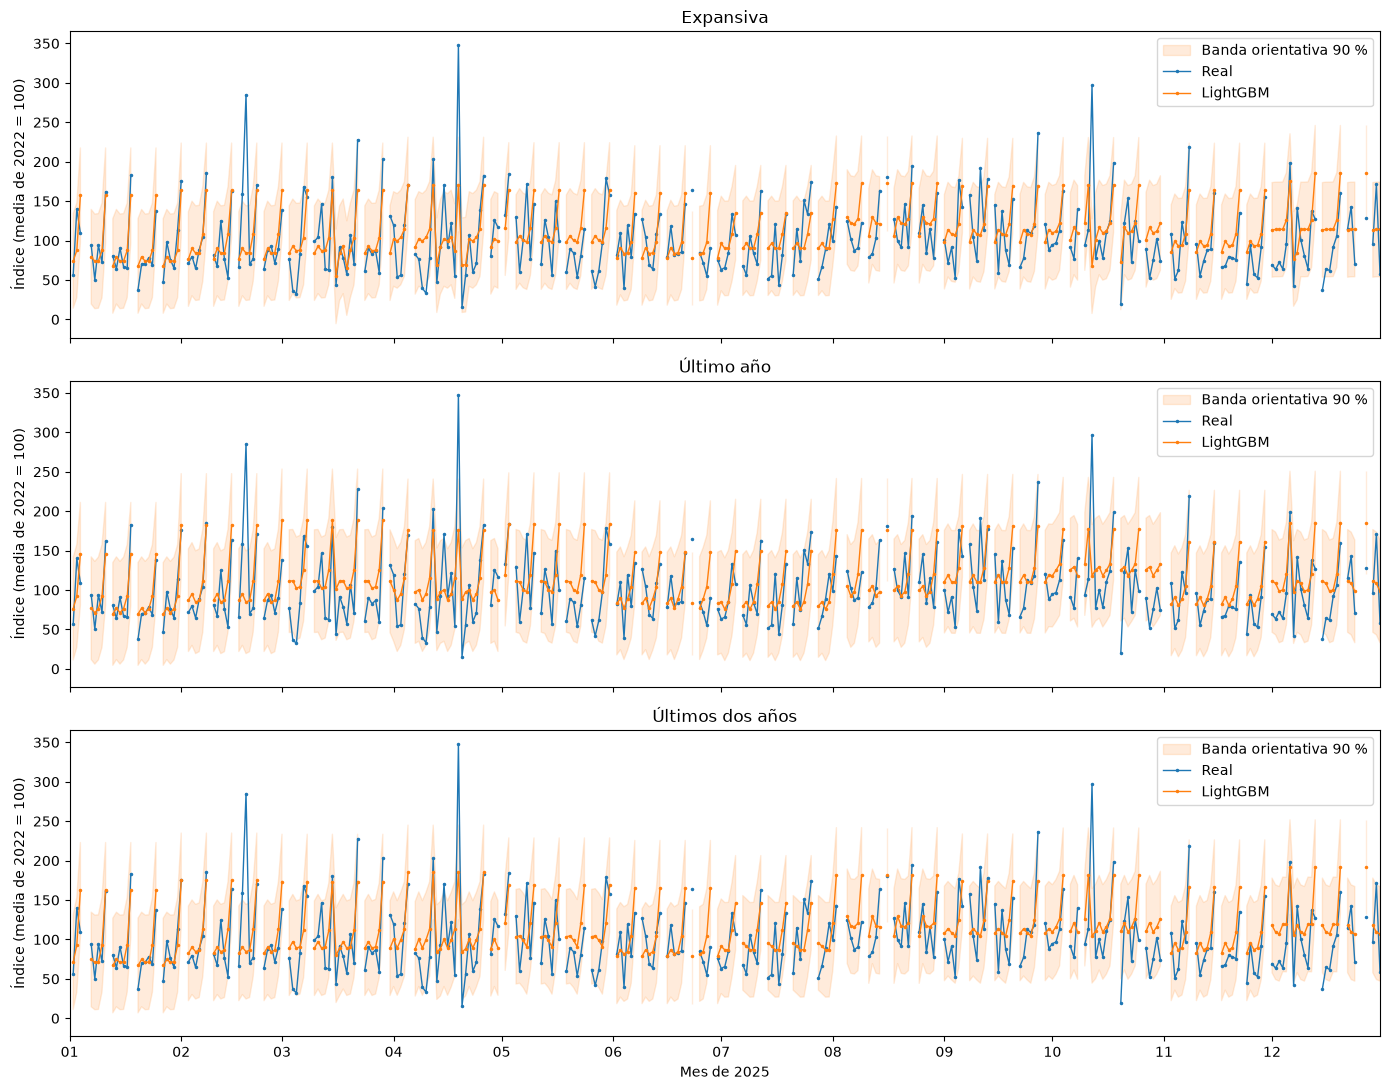

In [ ]:
margenes_ventanas = {nombre: np.quantile((resultado["indice"] - resultado["lightgbm"]).abs(), NIVEL_COBERTURA, method="higher") for nombre, resultado in ventanas_anuales.items()}
print("Cobertura y anchura de las bandas orientativas en 2025:")
display(pd.DataFrame({nombre: resumen_intervalo(resultado["indice"], resultado["lightgbm"] - margenes_ventanas[nombre], resultado["lightgbm"] + margenes_ventanas[nombre]) for nombre, resultado in ventanas_2025.items()}).T.round(2))

fig, ejes = plt.subplots(3, 1, figsize=(14, 11), sharex=True, sharey=True)
for ax, (nombre, resultado) in zip(ejes, ventanas_2025.items()):
    grafica = resultado.set_index("fecha").reindex(fechas_2025)
    margen = margenes_ventanas[nombre]
    ax.fill_between(grafica.index, grafica["lightgbm"] - margen, grafica["lightgbm"] + margen, color="C1", alpha=0.15, label="Banda orientativa 90 %")
    ax.plot(grafica.index, grafica["indice"], color="C0", marker=".", markersize=3, linewidth=1, label="Real")
    ax.plot(grafica.index, grafica["lightgbm"], color="C1", marker=".", markersize=3, linewidth=1, label="LightGBM")
    ax.set(title=nombre, ylabel="Índice (media de 2022 = 100)", xlim=(fechas_2025[0], fechas_2025[-1]))
    ax.legend()
ejes[-1].set_xlabel("Mes de 2025")
ejes[-1].xaxis.set_major_locator(mdates.MonthLocator())
ejes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m"))
fig.tight_layout()
plt.show()

## 6. Otros horizontes y frecuencias de validación

Para la configuración elegida en validación anual comparamos con el baseline usando un horizonte de **30 días naturales** con cortes cada 30 días y otro de **180 días naturales** con cortes cada 90 días. El primer pronóstico comienza el 1 de enero de 2023, tras al menos un año de entrenamiento. Cada corte usa todo el historial previo, predice el horizonte completo de una vez y evalúa solo días abiertos; se excluyen horizontes que terminen después de 2024.

Las métricas conjuntas se calculan sobre pares día-corte: en el horizonte de 180 días los periodos se solapan y un mismo día puede contarse más de una vez. Los cortes también comparten entrenamiento. Estos resultados no sustituyen la selección anual ni son directamente comparables con un pronóstico anual de 2025.

In [ ]:
esquemas_horizontes = [(30, 30), (180, 90)]
validaciones_horizontes = {}
filas_horizontes = []
for horizonte, periodo in esquemas_horizontes:
    cortes = pd.date_range("2023-01-01", "2024-12-31", freq=f"{periodo}D")
    cortes = [inicio for inicio in cortes if inicio + pd.Timedelta(days=horizonte - 1) <= pd.Timestamp("2024-12-31")]
    if not cortes:
        raise ValueError(f"No hay cortes completos para el horizonte de {horizonte} días.")
    resultados = []
    for inicio in cortes:
        fin = inicio + pd.Timedelta(days=horizonte - 1)
        resultado, _ = evaluar_periodo(datos, inicio, fin, CONFIGURACIONES[configuracion_elegida])
        resultado["corte"] = inicio
        resultados.append(resultado)
        resumen = comparar({configuracion_elegida: resultado}, nombre_referencia=configuracion_elegida).reset_index(names="Modelo")
        resumen["Horizonte (días)"] = horizonte
        resumen["Corte"] = inicio.date()
        resumen["Fin"] = fin.date()
        filas_horizontes.append(resumen)
    conjunto = pd.concat(resultados, ignore_index=True)
    validaciones_horizontes[horizonte] = conjunto
    print(f"Horizonte: {horizonte} días; periodo entre cortes: {periodo} días; cortes: {len(cortes)}")
    resumen = comparar({configuracion_elegida: conjunto}, nombre_referencia=configuracion_elegida).rename(columns={"Días abiertos": "Observaciones (día-corte)"})
    display(resumen.round(2))

print("Detalle por horizonte y corte:")
tabla_horizontes = pd.concat(filas_horizontes, ignore_index=True).set_index(["Horizonte (días)", "Corte", "Fin", "Modelo"])
with pd.option_context("display.max_rows", None):
    display(tabla_horizontes.round(2))

Horizonte: 30 días; periodo entre cortes: 30 días; cortes: 24


,Observaciones (día-corte),MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,610.0,28.69,31.61,25.78,-8.90
Inicial,610.0,27.08,32.05,24.32,-4.56


Horizonte: 180 días; periodo entre cortes: 90 días; cortes: 7


,Observaciones (día-corte),MAE (puntos de índice),MAPE (%),WAPE (%),Sesgo (puntos de índice)
Baseline: mediana día semanal,1067.0,29.28,32.21,26.12,-9.63
Inicial,1067.0,27.80,33.22,24.81,-4.59


Detalle por horizonte y corte:


Días abiertos  \
Horizonte (días) Corte      Fin        Modelo                                         
30               2023-01-01 2023-01-30 Baseline: mediana día semanal           25.0   
                                       Inicial                                 25.0   
                 2023-01-31 2023-03-01 Baseline: mediana día semanal           27.0   
                                       Inicial                                 27.0   
                 2023-03-02 2023-03-31 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2023-04-01 2023-04-30 Baseline: mediana día semanal           27.0   
                                       Inicial                                 27.0   
                 2023-05-01 2023-05-30 Baseline: mediana día semanal           27.0   
                                       Inicial                                 27.0   
                 2023-05-31 2023-06-29 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2023-06-30 2023-07-29 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2023-07-30 2023-08-28 Baseline: mediana día semanal           23.0   
                                       Inicial                                 23.0   
                 2023-08-29 2023-09-27 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2023-09-28 2023-10-27 Baseline: mediana día semanal           25.0   
                                       Inicial                                 25.0   
                 2023-10-28 2023-11-26 Baseline: mediana día semanal           24.0   
                                       Inicial                                 24.0   
                 2023-11-27 2023-12-26 Baseline: mediana día semanal           25.0   
                                       Inicial                                 25.0   
                 2023-12-27 2024-01-25 Baseline: mediana día semanal           25.0   
                                       Inicial                                 25.0   
                 2024-01-26 2024-02-24 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2024-02-25 2024-03-25 Baseline: mediana día semanal           24.0   
                                       Inicial                                 24.0   
                 2024-03-26 2024-04-24 Baseline: mediana día semanal           27.0   
                                       Inicial                                 27.0   
                 2024-04-25 2024-05-24 Baseline: mediana día semanal           25.0   
                                       Inicial                                 25.0   
                 2024-05-25 2024-06-23 Baseline: mediana día semanal           24.0   
                                       Inicial                                 24.0   
                 2024-06-24 2024-07-23 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2024-07-24 2024-08-22 Baseline: mediana día semanal           25.0   
                                       Inicial                                 25.0   
                 2024-08-23 2024-09-21 Baseline: mediana día semanal           26.0   
                                       Inicial                                 26.0   
                 2024-09-22 2024-10-21 Baseline: mediana día semanal           23.0   
                                       Inicial                                 23.0   
                 2024-10-22 2024-11-20 Baseline: mediana día semanal